# Customer Churn Analysis — Predictive Modeling (ANN)

**Project:** Customer Churn Analysis for Advanced Telecommunications Solutions (ATS)

**Notebook role:** Data Analyst — Predictive Modeling

**Author:** _[add name]_

### Purpose of this notebook

This notebook covers the **Stage 3-1 Predictive Modeling deliverables** from the project brief:

1. **Define the architecture of the ANN model**
2. **Train the model and optimise convergence**
3. **Predict customer churn based on critical attributes**
4. **Evaluate model performance and analyse predictions**

It also links the predictions back to the four customer segments from the Clustering Analysis (Part 2) and exports a churn-risk score for every customer for the Business Analyst's final report.

### Sprint / Task Mapping (Jira reference)

| Task | Notebook Section(s) |
|---|---|
| Load and validate the data received from the Data Engineer | Sections 1–2 |
| Prepare features, train/validation/test split, scaling | Section 3 |
| Establish baseline models | Section 4 |
| Define the ANN architecture | Section 5 |
| Train the ANN and optimise convergence | Section 6 |
| Evaluate model performance on the test set | Section 7 |
| Identify the critical attributes driving churn | Section 8 |
| Analyse predictions by segment and risk tier | Section 9 |
| Export model and predictions for downstream use | Section 10 |

### Data used in this notebook

- `../Data_Preparation/full_encoded_cleaned.csv`: the full cleaned and encoded dataset prepared by the **Data Engineer** (7,043 customers, 11 predictors + `Churn`, keyed by `row_id`, unscaled)
- `../Clustering_Analysis/cluster_assignments.csv`: the K-Means segment of every customer from Part 2, keyed by the same `row_id`

**A note on the ANN input files.** The Data Preparation notebook also describes `ann_train.csv` / `ann_test.csv`, but these were written to a `../data/processed/` folder that isn't in the project repository. Rather than depend on files that aren't there, this notebook rebuilds the **same 80/20 stratified split** (same `test_size`, `random_state` and stratification) from `full_encoded_cleaned.csv`, so it selects exactly the same test customers. One small change is deliberate: the scaler is fitted on the **training rows only** (in Data Preparation it was fitted on all 7,043 rows before the split). This keeps every piece of information about the test set out of the model until the final evaluation.

**Tooling.** The ANN is built with scikit-learn's `MLPClassifier`, a fully connected feed-forward neural network (multi-layer perceptron) trained by back-propagation. This keeps the project inside the libraries named in the brief (Pandas, NumPy, matplotlib, scikit-learn) and needs nothing extra installed. The network is trained **one epoch at a time** in Section 6 so convergence can be monitored and controlled directly.

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Load and validate the data received from the Data Engineer

## 1. Import Libraries

In [1]:
# Core data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling: the ANN (multi-layer perceptron) plus a simple baseline for comparison
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

# Evaluation and interpretation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss,
                             confusion_matrix, roc_curve, precision_recall_curve,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning

# File handling, model saving, utilities
import os
import json
import copy
import joblib
import warnings

# partial_fit() is called one epoch at a time in Section 6, which makes sklearn warn that
# each single call "has not converged". That is expected, so the warning is silenced.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
pd.set_option("display.max_columns", None)

# Output folders (created next to this notebook, inside Predictive_Modeling/)
for folder in ["Model", "Model_Training", "Model_Evaluation", "Predictions"]:
    os.makedirs(folder, exist_ok=True)

print("Libraries loaded.")

Libraries loaded.

## 2. Load and Validate the Data

As in Part 2, the files are treated as an external input and checked before modelling.

In [2]:
# Full cleaned + encoded dataset (unscaled), with row_id and the Churn target
full_df = pd.read_csv("../Data_Preparation/full_encoded_cleaned.csv")
print(f"full_df shape: {full_df.shape}")
full_df.head()

full_df shape: (7043, 13)

,row_id,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Churn,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,0,0,0,1,0,0,0,25,1,1,0,0
1,1,1,0,0,41,1,0,0,25,0,0,1,0
2,2,0,0,1,52,1,0,0,19,0,1,0,0
3,3,0,0,0,1,1,0,0,76,1,0,1,0
4,4,1,0,0,67,1,0,1,51,0,1,0,0


In [3]:
# Cluster assignments from Part 2, used in Section 10 to analyse predictions by segment
clusters_df = pd.read_csv("../Clustering_Analysis/cluster_assignments.csv")
print(f"clusters_df shape: {clusters_df.shape}")
clusters_df.head()

clusters_df shape: (7043, 3)

,row_id,cluster,cluster_label
0,0,1,"New, Low-Spend - Elevated Risk"
1,1,3,"Loyal, Low-Spend - Lowest Risk"
2,2,3,"Loyal, Low-Spend - Lowest Risk"
3,3,0,"New, High-Spend - Highest Risk"
4,4,3,"Loyal, Low-Spend - Lowest Risk"


**Validation checks:** the checks below make sure the data is safe to model on. They confirm no missing values, a unique `row_id`, a clean 1:1 join to the cluster file, 0/1 values in every encoded column, and exactly one contract type per customer (the one-hot encoding is consistent).

In [4]:
# 1. No missing values
assert full_df.isnull().sum().sum() == 0, "Missing values found!"

# 2. row_id is a unique key, and the cluster file joins 1:1 onto it
assert full_df["row_id"].is_unique, "row_id is not unique!"
_ = full_df.merge(clusters_df, on="row_id", how="left", validate="one_to_one")
assert set(full_df["row_id"]) == set(clusters_df["row_id"]), "row_id values differ between files!"

# 3. Every encoded categorical column only contains 0/1
binary_cols = ["gender", "SeniorCitizen", "Dependents", "PhoneService", "MultipleLines",
               "InternetService", "Churn",
               "Contract_Month-to-month", "Contract_One year", "Contract_Two year"]
for col in binary_cols:
    assert set(full_df[col].unique()) <= {0, 1}, f"{col} is not 0/1!"

# 4. Each customer has exactly one contract type
contract_cols = ["Contract_Month-to-month", "Contract_One year", "Contract_Two year"]
assert (full_df[contract_cols].sum(axis=1) == 1).all(), "Contract one-hot columns are inconsistent!"

print("All integrity checks passed: no missing values, unique row_id, clean 1:1 join to clusters,")
print("all binary columns are 0/1, and every customer has exactly one contract type.")
print(f"\nOverall churn rate: {full_df['Churn'].mean():.3f}  "
      f"({full_df['Churn'].sum():,} of {len(full_df):,} customers)")

All integrity checks passed: no missing values, unique row_id, clean 1:1 join to clusters,
all binary columns are 0/1, and every customer has exactly one contract type.

Overall churn rate: 0.265  (1,869 of 7,043 customers)

**Finding:** The data passes every check. The overall churn rate is **26.5%** (about 1 in 4 customers), so the classes are imbalanced. That has two consequences for this notebook:

- **Accuracy alone is misleading.** A model that predicts "no churn" for everyone would already be 73.5% accurate while catching zero churners. Recall, precision, F1 and ROC-AUC are used as the main metrics.
- **The decision threshold matters.** The default cut-off of 0.5 on predicted probability is rarely the best choice when only a quarter of customers churn, so it is tuned explicitly in Section 6.4.

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Prepare features, train/validation/test split, scaling

## 3. Feature Preparation

### 3.1 Input Features

All 11 encoded predictors are used. `Contract` keeps all three one-hot columns: a neural network isn't affected by the redundancy the way an unregularised linear model can be, and keeping all three makes the importance analysis in Section 8 easier to read.

In [5]:
TARGET = "Churn"
FEATURES = [c for c in full_df.columns if c not in ("row_id", TARGET)]

print(f"{len(FEATURES)} input features:")
for f in FEATURES:
    print(" -", f)

11 input features:
 - gender
 - SeniorCitizen
 - Dependents
 - tenure
 - PhoneService
 - MultipleLines
 - InternetService
 - MonthlyCharges
 - Contract_Month-to-month
 - Contract_One year
 - Contract_Two year

### 3.2 Train / Validation / Test Split

Three subsets, each with one job:

- **Train (64% of all customers):** the network learns its weights from these rows.
- **Validation (16%):** used to decide *when to stop training* (early stopping), to compare learning rates, and to choose the decision threshold.
- **Test (20%):** the same customers the Data Engineer set aside. They are used **once**, at the end, for the final performance figures.

All splits are stratified, so each keeps the 26.5% churn rate.

In [6]:
# Same split as the Data Engineer: 80/20, stratified on Churn, random_state=42.
# It depends only on the number of rows and the target, so it selects the same customers.
train_df, test_df = train_test_split(
    full_df, test_size=0.2, random_state=RANDOM_STATE, stratify=full_df[TARGET]
)

# Hold back 20% of the training portion as a validation set
train_sub_df, val_df = train_test_split(
    train_df, test_size=0.2, random_state=RANDOM_STATE, stratify=train_df[TARGET]
)

X_train_raw, y_train = train_sub_df[FEATURES], train_sub_df[TARGET].values
X_val_raw,   y_val   = val_df[FEATURES],       val_df[TARGET].values
X_test_raw,  y_test  = test_df[FEATURES],      test_df[TARGET].values

split_summary = pd.DataFrame({
    "rows": [len(train_sub_df), len(val_df), len(test_df)],
    "churn_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
    "used_for": ["Fitting the network weights",
                 "Early stopping, learning-rate check, decision threshold",
                 "Final, one-time evaluation only"],
}, index=["train", "validation", "test"]).round(3)
split_summary

,rows,churn_rate,used_for
train,4507,0.265,Fitting the network weights
validation,1127,0.265,"Early stopping, learning-rate check, decision threshold"
test,1409,0.265,"Final, one-time evaluation only"


### 3.3 Feature Scaling

Neural networks train faster and more reliably when inputs are on comparable scales. Without scaling, `tenure` (0–72) and `MonthlyCharges` (18–119) would dominate the 0/1 features in the early weight updates. `StandardScaler` is fitted on the training rows only and then applied unchanged to validation and test.

In [7]:
# Fit the scaler on the training rows only, then apply the same transformation everywhere
scaler = StandardScaler().fit(X_train_raw)

X_train = scaler.transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

print("Training features after scaling (mean ~0, std ~1):")
pd.DataFrame(X_train, columns=FEATURES).describe().loc[["mean", "std"]].round(2)

Training features after scaling (mean ~0, std ~1):

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Contract_Month-to-month,Contract_One year,Contract_Two year
mean,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 3.4 Duplicate-Row Check

Data Preparation found 302 duplicate row patterns and kept them, because without a customer ID there's no way to tell whether they are the same customer twice. For a predictive model this matters: if a test customer has an identical twin in the training data, the model has in effect "seen" that answer. The overlap is measured here, and its effect on the results is checked in Section 7.5.

In [8]:
# How many test customers have an identical twin (same 11 features AND same Churn) in the training portion?
key_cols = FEATURES + [TARGET]
train_patterns = set(map(tuple, train_df[key_cols].values))
test_has_twin = np.array([tuple(r) in train_patterns for r in test_df[key_cols].values])

print(f"Test rows with an identical copy in the training data: {test_has_twin.sum()} "
      f"of {len(test_df)} ({test_has_twin.mean():.1%})")

Test rows with an identical copy in the training data: 93 of 1409 (6.6%)

**Finding:** About 6.6% of test customers have an exact copy in the training data. That is small, but large enough to check whether it inflates the scores (Section 7.5).

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Establish baseline models

## 4. Baseline Models

An ANN is only worth its extra complexity if it beats simpler approaches. Two baselines are set:

1. **Majority class:** always predict "No churn". This is the floor any useful model must clear.
2. **Logistic regression:** the standard, interpretable linear model for a yes/no outcome. If the ANN can't beat this, the relationship in the data is essentially linear.

In [9]:
# Baseline 1: always predict "No churn" (the majority class)
majority_acc = 1 - y_val.mean()

# Baseline 2: logistic regression on the same scaled features.
# class_weight="balanced" stops it from simply favouring the majority class.
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)
p_val_lr = log_reg.predict_proba(X_val)[:, 1]

print(f"Majority-class baseline — validation accuracy: {majority_acc:.3f}  (recall for churners: 0.000)")
print(f"Logistic regression     — validation ROC-AUC:  {roc_auc_score(y_val, p_val_lr):.3f}")

Majority-class baseline — validation accuracy: 0.735  (recall for churners: 0.000)
Logistic regression     — validation ROC-AUC:  0.823

**Finding:** Logistic regression already reaches a validation ROC-AUC of about **0.82**, which is a strong reference point. The ANN is compared against it throughout.

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Define the ANN architecture

## 5. Define the ANN Architecture

### 5.1 Architecture Search (5-fold cross-validation)

Rather than picking a network shape arbitrarily, several candidate architectures are compared systematically on the training data, using 5-fold stratified cross-validation scored by ROC-AUC:

| Hyperparameter | Options tested | Why it matters |
|---|---|---|
| Hidden layers (neurons) | (8), (16), (32), (16, 8), (32, 16), (64, 32) | Network depth and width, i.e. how complex a pattern it can learn |
| Activation | ReLU, tanh | The non-linearity applied in each hidden neuron |
| L2 penalty (`alpha`) | 0.0001, 0.01, 0.1 | Regularisation against overfitting |
| Initial learning rate | 0.001, 0.01 | Step size of the Adam optimiser |

The scaler sits inside a `Pipeline`, so each fold re-fits it on that fold's training part only. Every run uses built-in early stopping, so no configuration is penalised for training too long. The validation and test sets are not touched here.

In [10]:
# Pipeline = scaler + ANN, so each CV fold re-fits the scaler on its own training rows only
search_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPClassifier(solver="adam", batch_size=64, max_iter=500,
                          early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
                          random_state=RANDOM_STATE)),
])

param_grid = {
    "ann__hidden_layer_sizes": [(8,), (16,), (32,), (16, 8), (32, 16), (64, 32)],
    "ann__activation": ["relu", "tanh"],
    "ann__alpha": [1e-4, 1e-2, 1e-1],              # L2 regularisation strength
    "ann__learning_rate_init": [1e-3, 1e-2],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(search_pipe, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train_raw, y_train)

n_combos = len(grid.cv_results_["params"])
print(f"Tested {n_combos} configurations x 5 folds = {n_combos * 5} training runs.")
print(f"Best mean CV ROC-AUC: {grid.best_score_:.4f}")
print("Best configuration:", {k.replace("ann__", ""): v for k, v in grid.best_params_.items()})

Tested 72 configurations x 5 folds = 360 training runs.
Best mean CV ROC-AUC: 0.8188
Best configuration: {'activation': 'tanh', 'alpha': 0.1, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.001}

In [11]:
grid_results = pd.DataFrame(grid.cv_results_)
grid_results = grid_results[[
    "param_ann__hidden_layer_sizes", "param_ann__activation", "param_ann__alpha",
    "param_ann__learning_rate_init", "mean_test_score", "std_test_score", "rank_test_score"
]].rename(columns=lambda c: c.replace("param_ann__", "").replace("mean_test_score", "cv_auc_mean")
                              .replace("std_test_score", "cv_auc_std").replace("rank_test_score", "rank"))
grid_results["hidden_layer_sizes"] = grid_results["hidden_layer_sizes"].astype(str)
grid_results = grid_results.sort_values("rank").reset_index(drop=True)
grid_results.to_csv("Model_Training/architecture_search_results.csv", index=False)

grid_results.head(10).round(4)

,hidden_layer_sizes,activation,alpha,learning_rate_init,cv_auc_mean,cv_auc_std,rank
0,"(32, 16)",tanh,0.1000,0.001,0.8188,0.0249,1
1,"(64, 32)",tanh,0.1000,0.001,0.8185,0.0239,2
2,"(16, 8)",tanh,0.1000,0.010,0.8175,0.0222,3
3,"(8,)",relu,0.1000,0.010,0.8167,0.0248,4
4,"(16,)",tanh,0.0100,0.001,0.8166,0.0242,5
5,"(16,)",tanh,0.0001,0.001,0.8166,0.0242,6
6,"(16,)",tanh,0.1000,0.010,0.8165,0.0225,7
7,"(16,)",tanh,0.1000,0.001,0.8163,0.0248,8
8,"(8,)",tanh,0.0001,0.001,0.8159,0.0278,9
9,"(8,)",tanh,0.1000,0.001,0.8158,0.0286,10


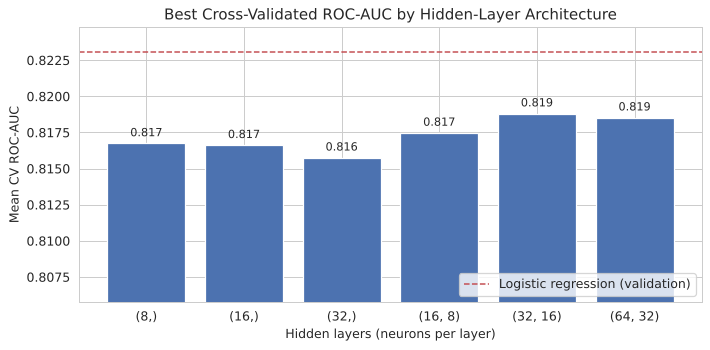

In [12]:
# Best CV score achieved by each architecture (over all other settings)
best_per_arch = (grid_results.groupby("hidden_layer_sizes")["cv_auc_mean"].max()
                 .reindex(["(8,)", "(16,)", "(32,)", "(16, 8)", "(32, 16)", "(64, 32)"]))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(best_per_arch.index, best_per_arch.values, color="#4C72B0")
ax.axhline(roc_auc_score(y_val, p_val_lr), color="#C44E52", ls="--", lw=1.2,
           label="Logistic regression (validation)")
ax.set_ylim(best_per_arch.min() - 0.01, best_per_arch.max() + 0.006)
ax.set_title("Best Cross-Validated ROC-AUC by Hidden-Layer Architecture")
ax.set_xlabel("Hidden layers (neurons per layer)")
ax.set_ylabel("Mean CV ROC-AUC")
for b, v in zip(bars, best_per_arch.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.0005, f"{v:.3f}", ha="center", fontsize=9)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("Model_Training/architecture_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:**
- The best configuration is **two hidden layers (32 → 16 neurons), tanh activation, strong L2 regularisation (alpha = 0.1), learning rate 0.001**, with a mean CV ROC-AUC of about **0.819**.
- The differences between architectures are **very small**. The top 10 configurations sit within about 0.003 AUC of each other, well inside the fold-to-fold standard deviation (about 0.024). Even the single-hidden-layer (8) network is close to the best.
- The strongest regularisation (alpha = 0.1) appears repeatedly near the top. This suggests the extra capacity of larger networks mostly fits noise in this dataset.
- **Interpretation:** with 11 inputs, 9 of them binary, there is little complex non-linear structure for a deeper network to exploit. The two-layer network is kept as the final architecture because it scored best, but in practice a small network is sufficient.

### 5.2 Final Architecture

In [13]:
best_params = {k.replace("ann__", ""): v for k, v in grid.best_params_.items()}

def build_ann(learning_rate_init=None):
    """Create the ANN with the selected architecture (untrained)."""
    params = dict(best_params)
    if learning_rate_init is not None:
        params["learning_rate_init"] = learning_rate_init
    return MLPClassifier(**params, solver="adam", batch_size=64, shuffle=True,
                         random_state=RANDOM_STATE)

layers = [len(FEATURES)] + list(best_params["hidden_layer_sizes"]) + [1]
n_weights = sum(a * b + b for a, b in zip(layers[:-1], layers[1:]))  # weights + biases

print("ANN architecture")
print("-" * 52)
print(f"Input layer      : {len(FEATURES)} neurons (one per feature)")
for i, n in enumerate(best_params["hidden_layer_sizes"], 1):
    print(f"Hidden layer {i}   : {n} neurons, {best_params['activation']} activation")
print(f"Output layer     : 1 neuron, logistic (sigmoid) -> P(churn)")
print("-" * 52)
print(f"Trainable parameters : {n_weights}")
print(f"Loss function        : binary cross-entropy (log-loss)")
print(f"Optimiser            : Adam, initial learning rate {best_params['learning_rate_init']}")
print(f"L2 regularisation    : alpha = {best_params['alpha']}")
print(f"Mini-batch size      : 64")

ANN architecture
----------------------------------------------------
Input layer      : 11 neurons (one per feature)
Hidden layer 1   : 32 neurons, tanh activation
Hidden layer 2   : 16 neurons, tanh activation
Output layer     : 1 neuron, logistic (sigmoid) -> P(churn)
----------------------------------------------------
Trainable parameters : 929
Loss function        : binary cross-entropy (log-loss)
Optimiser            : Adam, initial learning rate 0.001
L2 regularisation    : alpha = 0.1
Mini-batch size      : 64

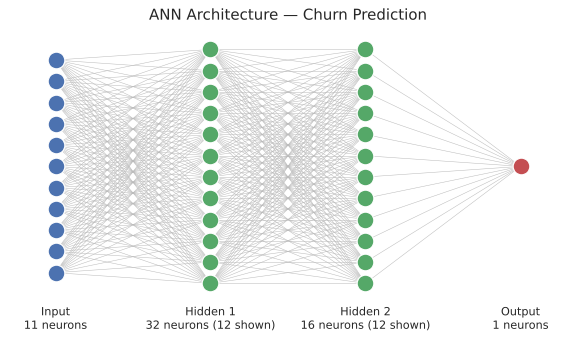

In [14]:
# Simple diagram of the network
def draw_network(layer_sizes, ax, max_draw=12):
    labels = (["Input"] + [f"Hidden {i}" for i in range(1, len(layer_sizes) - 1)] + ["Output"])
    xs = np.linspace(0, 1, len(layer_sizes))
    coords = []
    for x, n in zip(xs, layer_sizes):
        shown = min(n, max_draw)
        ys = np.linspace(0.5 - 0.42 * (shown - 1) / max(max_draw - 1, 1),
                         0.5 + 0.42 * (shown - 1) / max(max_draw - 1, 1), shown)
        coords.append([(x, y) for y in ys])
    for a, b in zip(coords[:-1], coords[1:]):
        for (x1, y1) in a:
            for (x2, y2) in b:
                ax.plot([x1, x2], [y1, y2], color="#BBBBBB", lw=0.4, zorder=1)
    colours = ["#4C72B0"] + ["#55A868"] * (len(layer_sizes) - 2) + ["#C44E52"]
    for (pts, n, lab, col) in zip(coords, layer_sizes, labels, colours):
        ax.scatter([p[0] for p in pts], [p[1] for p in pts], s=180, color=col, zorder=2, edgecolor="white")
        note = f"{lab}\n{n} neurons" + (" (12 shown)" if n > max_draw else "")
        ax.text(pts[0][0], 0.0, note, ha="center", va="top", fontsize=9)
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.12, 1.0); ax.axis("off")

fig, ax = plt.subplots(figsize=(8, 4.5))
draw_network(layers, ax)
ax.set_title("ANN Architecture — Churn Prediction")
plt.savefig("Model_Training/ann_architecture.png", dpi=300, bbox_inches="tight")
plt.show()

**Architecture summary:**

| Layer | Neurons | Activation | Role |
|---|---|---|---|
| Input | 11 | — | One neuron per customer attribute (scaled) |
| Hidden 1 | 32 | tanh | Learns combinations of attributes (e.g. new customer + high bill) |
| Hidden 2 | 16 | tanh | Combines those patterns into higher-level risk signals |
| Output | 1 | sigmoid | Outputs the **probability of churn** (0–1) |

- **Loss:** binary cross-entropy (log-loss), the standard loss for yes/no classification
- **Optimiser:** Adam (adaptive learning rate per weight), with mini-batches of 64 customers
- **Regularisation:** L2 weight penalty (alpha = 0.1) plus early stopping (Section 6)

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Train the ANN and optimise convergence

## 6. Train the ANN and Optimise Convergence

### 6.1 Training Loop with Early Stopping

The network is trained **one epoch (one full pass over the training data) at a time** with `partial_fit()`. After each epoch, the loss and ROC-AUC are recorded on both the training and validation sets. Training stops once validation loss hasn't improved for **25 consecutive epochs**, and the weights from the **best epoch** (lowest validation loss) are kept.

This controls convergence in two ways. It stops training before the network starts memorising the training data (overfitting), and it produces the learning curves that show whether training converged properly.

In [15]:
def train_with_monitoring(model, X_tr, y_tr, X_va, y_va, max_epochs=400, patience=25, min_delta=1e-4):
    """Train one epoch at a time; keep the epoch with the lowest validation loss (early stopping)."""
    history, best_model, best_loss, best_epoch, wait = [], None, np.inf, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.partial_fit(X_tr, y_tr, classes=[0, 1])
        p_tr, p_va = model.predict_proba(X_tr)[:, 1], model.predict_proba(X_va)[:, 1]
        val_loss = log_loss(y_va, p_va)
        history.append({"epoch": epoch,
                        "train_loss": log_loss(y_tr, p_tr), "val_loss": val_loss,
                        "train_auc": roc_auc_score(y_tr, p_tr), "val_auc": roc_auc_score(y_va, p_va)})
        if val_loss < best_loss - min_delta:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_model = copy.deepcopy(model)
        else:
            wait += 1
            if wait >= patience:
                break
    return best_model, pd.DataFrame(history), best_epoch

### 6.2 Learning-Rate Comparison

The learning rate is the setting with the biggest effect on convergence. Too small and training crawls; too large and the loss bounces around without settling. Four values are compared on the validation set using the architecture from Section 5.

In [16]:
lr_candidates = [1e-4, 1e-3, 1e-2, 5e-2]
lr_runs = {}
for lr in lr_candidates:
    m, hist, best_ep = train_with_monitoring(build_ann(lr), X_train, y_train, X_val, y_val)
    lr_runs[lr] = {"model": m, "history": hist, "best_epoch": best_ep}

lr_summary = pd.DataFrame([{
    "learning_rate": lr,
    "epochs_run": len(r["history"]),
    "best_epoch": r["best_epoch"],
    "best_val_loss": r["history"]["val_loss"].min(),
    "val_auc_at_best": r["history"].loc[r["best_epoch"] - 1, "val_auc"],
} for lr, r in lr_runs.items()]).round(4)
lr_summary

,learning_rate,epochs_run,best_epoch,best_val_loss,val_auc_at_best
0,0.0001,400,392,0.4370,0.8252
1,0.0010,140,115,0.4348,0.8280
2,0.0100,58,33,0.4355,0.8286
3,0.0500,62,37,0.4476,0.8178


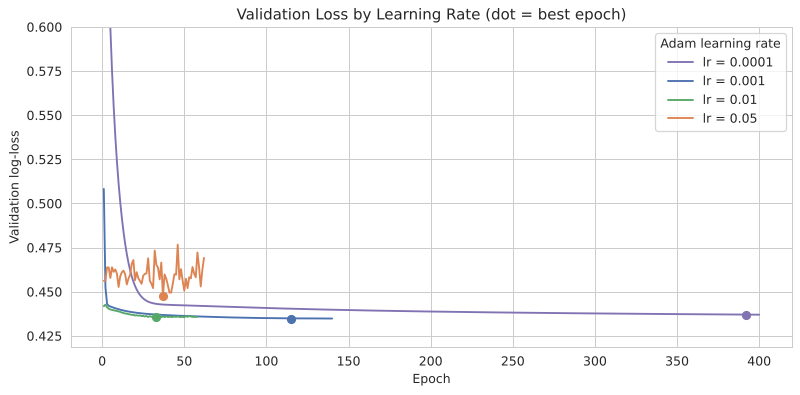

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colours = ["#8172B3", "#4C72B0", "#55A868", "#DD8452"]
for (lr, r), col in zip(lr_runs.items(), colours):
    ax.plot(r["history"]["epoch"], r["history"]["val_loss"], color=col, label=f"lr = {lr:g}")
    ax.scatter(r["best_epoch"], r["history"]["val_loss"].min(), color=col, s=40, zorder=3)
ax.set_title("Validation Loss by Learning Rate (dot = best epoch)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation log-loss")
ax.set_ylim(top=min(0.6, ax.get_ylim()[1]))
ax.legend(title="Adam learning rate")
plt.tight_layout()
plt.savefig("Model_Training/learning_rate_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:**
- **lr = 0.0001** converges smoothly but very slowly. It used the full 400-epoch budget and was still creeping downwards, so it is inefficient.
- **lr = 0.001** and **lr = 0.01** both converge cleanly to almost the same validation loss (about 0.435). 0.01 gets there in about a quarter of the epochs.
- **lr = 0.05** is too aggressive. Validation loss oscillates and settles at a clearly worse level (about 0.448), the classic sign of an optimiser overshooting the minimum.
- **Decision:** the final model uses the learning rate with the lowest validation loss, **0.001**. This agrees with the cross-validated choice in Section 5.1, and its smooth curve makes it the more stable option. 0.01 would be an equally valid, faster alternative.

In [18]:
# Final model = the learning rate with the lowest validation loss
final_lr = lr_summary.loc[lr_summary["best_val_loss"].idxmin(), "learning_rate"]
ann = lr_runs[final_lr]["model"]
history = lr_runs[final_lr]["history"]
best_epoch = lr_runs[final_lr]["best_epoch"]
history.to_csv("Model_Training/training_history.csv", index=False)

print(f"Selected learning rate: {final_lr:g}")
print(f"Best epoch: {best_epoch} (training stopped at epoch {len(history)}, "
      f"after {len(history) - best_epoch} epochs with no improvement)")
print(f"Validation log-loss at best epoch: {history['val_loss'].min():.4f}")
print(f"Validation ROC-AUC at best epoch:  {history.loc[best_epoch - 1, 'val_auc']:.4f}")

Selected learning rate: 0.001
Best epoch: 115 (training stopped at epoch 140, after 25 epochs with no improvement)
Validation log-loss at best epoch: 0.4348
Validation ROC-AUC at best epoch:  0.8280

### 6.3 Learning Curves of the Final Model

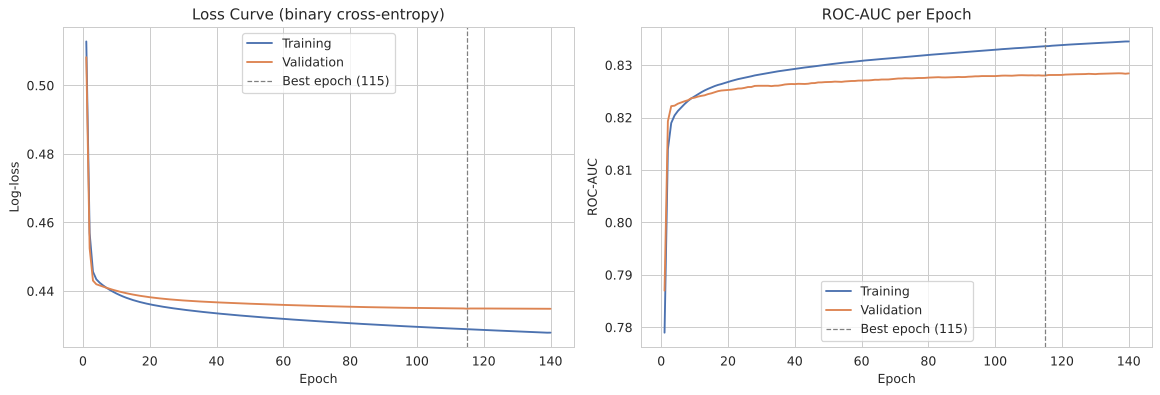

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["epoch"], history["train_loss"], label="Training", color="#4C72B0")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation", color="#DD8452")
axes[0].axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
axes[0].set_title("Loss Curve (binary cross-entropy)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Log-loss"); axes[0].legend()

axes[1].plot(history["epoch"], history["train_auc"], label="Training", color="#4C72B0")
axes[1].plot(history["epoch"], history["val_auc"], label="Validation", color="#DD8452")
axes[1].axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
axes[1].set_title("ROC-AUC per Epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("ROC-AUC"); axes[1].legend()

plt.tight_layout()
plt.savefig("Model_Training/training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:**
- Both training and validation loss fall steeply in the first ~5 epochs and then flatten. The model learns most of what it can very quickly, and the rest is fine-tuning.
- The gap between training and validation stays **small** (about 0.006 log-loss at the best epoch), and validation loss never turns back upward. There is no meaningful overfitting, helped by the L2 penalty and early stopping.
- Validation ROC-AUC plateaus around **0.83**. The model has converged: more epochs would not improve it.

### 6.4 Choosing the Decision Threshold

The ANN outputs a churn **probability**, and a cut-off turns it into a yes/no prediction. With a 26.5% churn rate, the default 0.5 is conservative: it flags only customers the model is very sure about, so many churners are missed.

The threshold is chosen on the **validation set** (not the test set) as the value that maximises **F1**, the balance of precision and recall.

In [20]:
p_val_ann = ann.predict_proba(X_val)[:, 1]

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
thr_df = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_val, p_val_ann >= t, zero_division=0) for t in thresholds],
    "recall":    [recall_score(y_val, p_val_ann >= t) for t in thresholds],
    "f1":        [f1_score(y_val, p_val_ann >= t) for t in thresholds],
})
best_threshold = float(thr_df.loc[thr_df["f1"].idxmax(), "threshold"])

# The same procedure for the logistic regression baseline, so the comparison is fair
lr_f1 = [f1_score(y_val, p_val_lr >= t) for t in thresholds]
lr_threshold = float(thresholds[int(np.argmax(lr_f1))])

print(f"ANN decision threshold (max validation F1): {best_threshold:.2f}")
print(thr_df.set_index("threshold").loc[[0.5, best_threshold]].round(3))

ANN decision threshold (max validation F1): 0.24
           precision  recall     f1
threshold                          
0.50           0.654   0.538  0.591
0.24           0.490   0.819  0.613

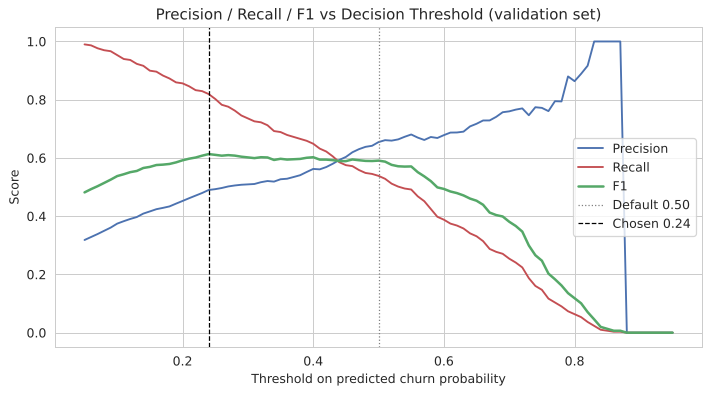

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thr_df["threshold"], thr_df["precision"], label="Precision", color="#4C72B0")
ax.plot(thr_df["threshold"], thr_df["recall"], label="Recall", color="#C44E52")
ax.plot(thr_df["threshold"], thr_df["f1"], label="F1", color="#55A868", lw=2)
ax.axvline(0.5, color="grey", ls=":", lw=1, label="Default 0.50")
ax.axvline(best_threshold, color="black", ls="--", lw=1, label=f"Chosen {best_threshold:.2f}")
ax.set_title("Precision / Recall / F1 vs Decision Threshold (validation set)")
ax.set_xlabel("Threshold on predicted churn probability")
ax.set_ylabel("Score")
ax.legend(loc="center right")
plt.tight_layout()
plt.savefig("Model_Training/threshold_selection.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:** Lowering the threshold from 0.50 to **0.24** raises validation recall from about 54% to about 82% (many more churners caught), at the cost of lower precision (more loyal customers flagged too).

**Business rationale:** for retention, missing a churner (lost revenue) usually costs much more than contacting a customer who would have stayed (the cost of an offer or a call). So a recall-leaning threshold is the right default. The threshold is a business lever and can be raised if the retention budget only allows a smaller, more targeted campaign (see the risk tiers in Section 9.2).

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Evaluate model performance on the test set

## 7. Evaluate Model Performance (Test Set)

Everything up to this point (architecture, learning rate, epochs, threshold) was decided without looking at the test set. The test customers are now scored once to get an honest estimate of how the model will perform on new customers.

### 7.1 Headline Metrics vs Baselines

In [22]:
p_test_ann = ann.predict_proba(X_test)[:, 1]
p_test_lr = log_reg.predict_proba(X_test)[:, 1]
pred_test_ann = (p_test_ann >= best_threshold).astype(int)

def metrics_row(name, y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {"model": name, "threshold": threshold,
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, prob) if prob.std() > 0 else 0.5,
            "pr_auc": average_precision_score(y_true, prob)}

test_metrics = pd.DataFrame([
    metrics_row("Majority class (always 'No')", y_test, np.zeros(len(y_test)), 0.5),
    metrics_row("Logistic regression", y_test, p_test_lr, lr_threshold),
    metrics_row("ANN (default threshold)", y_test, p_test_ann, 0.5),
    metrics_row("ANN (tuned threshold)", y_test, p_test_ann, best_threshold),
]).set_index("model").round(3)

test_metrics.to_csv("Model_Evaluation/test_metrics.csv")
test_metrics

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Majority class (always 'No'),0.50,0.735,0.000,0.000,0.000,0.500,0.265
Logistic regression,0.60,0.753,0.528,0.650,0.583,0.807,0.605
ANN (default threshold),0.50,0.784,0.615,0.495,0.548,0.807,0.598
ANN (tuned threshold),0.24,0.696,0.456,0.757,0.569,0.807,0.598


**How to read this table:**
- **Recall:** share of actual churners the model catches. **Precision:** share of flagged customers who really churn.
- **ROC-AUC:** how well the model *ranks* churners above non-churners, independent of any threshold (0.5 = random, 1.0 = perfect).
- **PR-AUC:** like ROC-AUC but focused on the churn class (random = 0.265 here).

**Finding:**
- The ANN is clearly useful. A test ROC-AUC of **0.807** means that for a random churner/non-churner pair, the model ranks the churner as riskier about 81% of the time. PR-AUC (0.60) is more than double the random level (0.265).
- At the tuned threshold the ANN **catches about 76% of churners** (283 of 374), compared with 0% for the majority-class baseline.
- Accuracy at the tuned threshold (69.6%) is *lower* than the majority baseline (73.5%). This is expected and is exactly why accuracy isn't the target metric here: the model deliberately accepts more false alarms in exchange for catching most churners. At the default 0.5 threshold accuracy rises to 78.4%, but recall drops to about 50%.
- **The ANN performs on par with logistic regression, not better.** The two have the same test ROC-AUC (0.807), and logistic regression is marginally ahead on F1 (0.583 vs 0.569). This matches the architecture search: the churn signal in these 11 attributes is close to linear, so the ANN's extra flexibility brings no measurable gain. That is a useful result for the final report. The ANN meets the brief, but a simpler model would be equally accurate and easier to explain.

### 7.2 Classification Report

In [23]:
print(f"ANN — classification report on the test set (threshold {best_threshold:.2f})\n")
print(classification_report(y_test, pred_test_ann, target_names=["Stayed (0)", "Churned (1)"], digits=3))

ANN — classification report on the test set (threshold 0.24)

              precision    recall  f1-score   support

  Stayed (0)      0.885     0.674     0.765      1035
 Churned (1)      0.456     0.757     0.569       374

    accuracy                          0.696      1409
   macro avg      0.671     0.716     0.667      1409
weighted avg      0.771     0.696     0.713      1409

### 7.3 Confusion Matrix

True positives  (churners caught):         283
False negatives (churners missed):         91
False positives (loyal customers flagged): 337
True negatives  (loyal, correctly clear):  698

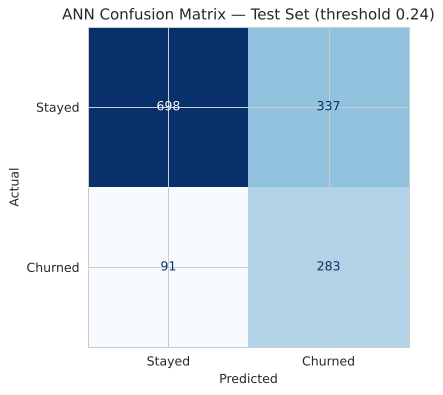

In [24]:
cm = confusion_matrix(y_test, pred_test_ann)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"ANN Confusion Matrix — Test Set (threshold {best_threshold:.2f})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("Model_Evaluation/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"True positives  (churners caught):         {tp}")
print(f"False negatives (churners missed):         {fn}")
print(f"False positives (loyal customers flagged): {fp}")
print(f"True negatives  (loyal, correctly clear):  {tn}")

**Finding:** Of the 374 churners in the test set, the model catches **283** and misses **91**. The cost is **337** false alarms among the 1,035 customers who stayed. In practice, about 45 in every 100 flagged customers would really churn, compared with 26.5 in 100 if customers were picked at random.

### 7.4 ROC and Precision-Recall Curves

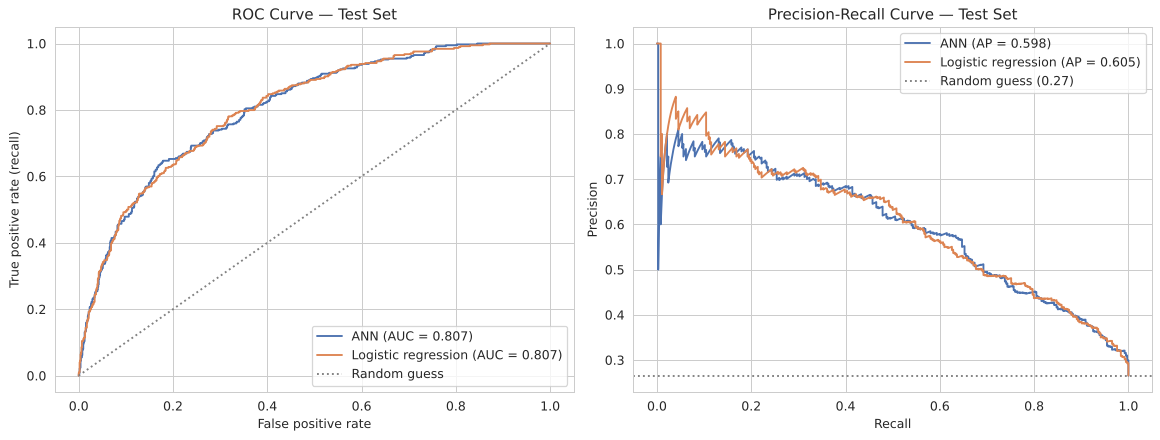

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for prob, name, col in [(p_test_ann, "ANN", "#4C72B0"), (p_test_lr, "Logistic regression", "#DD8452")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=col, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rec, prec, color=col, label=f"{name} (AP = {average_precision_score(y_test, prob):.3f})")

axes[0].plot([0, 1], [0, 1], color="grey", ls=":", label="Random guess")
axes[0].set_title("ROC Curve — Test Set"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(loc="lower right")

axes[1].axhline(y_test.mean(), color="grey", ls=":", label=f"Random guess ({y_test.mean():.2f})")
axes[1].set_title("Precision-Recall Curve — Test Set"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("Model_Evaluation/roc_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:** The ANN and logistic-regression curves almost overlap across the whole range, confirming that the two models rank customers almost identically. Both sit well above the random-guess line.

### 7.5 Robustness Checks

**Calibration:** can the predicted probability be read literally? (E.g. do customers scored at 40% really churn about 40% of the time?)

Brier score (lower is better): 0.1487

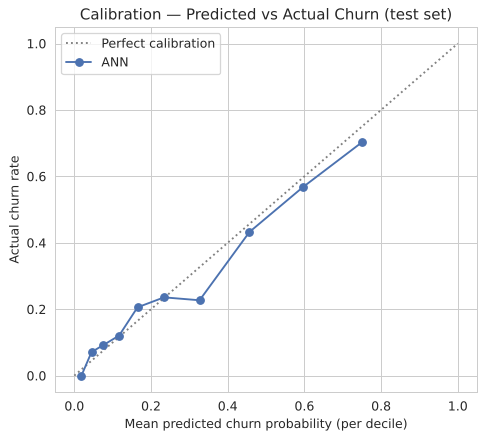

In [26]:
frac_pos, mean_pred = calibration_curve(y_test, p_test_ann, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="grey", ls=":", label="Perfect calibration")
ax.plot(mean_pred, frac_pos, marker="o", color="#4C72B0", label="ANN")
ax.set_title("Calibration — Predicted vs Actual Churn (test set)")
ax.set_xlabel("Mean predicted churn probability (per decile)")
ax.set_ylabel("Actual churn rate")
ax.legend()
plt.tight_layout()
plt.savefig("Model_Evaluation/calibration_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Brier score (lower is better): {np.mean((p_test_ann - y_test) ** 2):.4f}")

**Finding:** The calibration curve tracks the diagonal closely, so the probabilities are well calibrated and can be used directly as "chance of churn" figures in the business report (this is used for the risk tiers in Section 9).

**Duplicate rows:** does the 6.6% of test customers with an identical twin in the training data inflate the results?

In [27]:
unseen = ~test_has_twin
dup_eval = pd.DataFrame([
    metrics_row("All test rows", y_test, p_test_ann, best_threshold) | {"rows": len(y_test)},
    metrics_row("Rows with no identical copy in training", y_test[unseen], p_test_ann[unseen], best_threshold) | {"rows": int(unseen.sum())},
]).set_index("model")[["rows", "accuracy", "precision", "recall", "f1", "roc_auc"]].round(3)
dup_eval

,rows,accuracy,precision,recall,f1,roc_auc
model,,,,,,
All test rows,1409,0.696,0.456,0.757,0.569,0.807
Rows with no identical copy in training,1316,0.684,0.443,0.748,0.557,0.795


**Finding:** Removing those rows lowers ROC-AUC only slightly (0.807 → 0.795) and recall barely moves (75.7% → 74.8%). The duplicates are not materially inflating the results, and the model generalises to genuinely unseen customer profiles.

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Identify the critical attributes driving churn

## 8. Critical Attributes Driving Churn

Neural networks don't have simple coefficients, so two model-agnostic methods are used to explain what the ANN relies on.

### 8.1 Permutation Importance

Each feature is randomly shuffled in the test set (breaking its link to churn), and the drop in ROC-AUC is measured. The bigger the drop, the more the model depends on that feature. This is repeated 30 times per feature.

In [28]:
# Pipeline = fitted scaler + fitted ANN, so features can be shuffled in their original units
ann_pipeline = Pipeline([("scaler", scaler), ("ann", ann)])

perm = permutation_importance(ann_pipeline, X_test_raw, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = (pd.DataFrame({"feature": FEATURES,
                               "auc_drop_mean": perm.importances_mean,
                               "auc_drop_std": perm.importances_std})
                 .sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))
importance_df.to_csv("Model_Evaluation/feature_importance.csv", index=False)
importance_df.round(4)

,feature,auc_drop_mean,auc_drop_std
0,tenure,0.2008,0.0132
1,MonthlyCharges,0.1177,0.0093
2,SeniorCitizen,0.0100,0.0026
3,PhoneService,0.0082,0.0018
4,Dependents,0.0014,0.0018
5,InternetService,0.0008,0.0011
6,Contract_Month-to-month,0.0008,0.0014
7,Contract_One year,0.0007,0.0014
8,Contract_Two year,-0.0001,0.0006
9,gender,-0.0007,0.0014


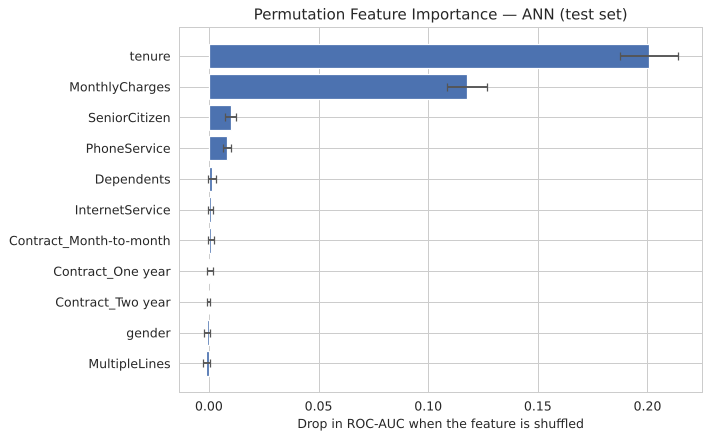

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = importance_df.iloc[::-1]
ax.barh(plot_df["feature"], plot_df["auc_drop_mean"], xerr=plot_df["auc_drop_std"],
        color="#4C72B0", ecolor="#555555", capsize=3)
ax.set_title("Permutation Feature Importance — ANN (test set)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig("Model_Evaluation/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:**
- **Tenure is by far the most important attribute.** Shuffling it drops ROC-AUC by about 0.20, which is most of the model's predictive power.
- **MonthlyCharges is clearly second** (a drop of about 0.12).
- **SeniorCitizen** and **PhoneService** add a small but real amount (about 0.01 each).
- **Contract type, InternetService, gender, MultipleLines and Dependents add almost nothing** once tenure and charges are known. Their importance is within noise of zero.

This strongly supports the Clustering Analysis, which segmented customers on tenure and MonthlyCharges alone: the ANN, given all 11 attributes, independently arrives at the same two as the key drivers.

**Note on Contract:** in many telecom datasets contract type is a major churn driver. In this dataset it isn't. Raw churn rates are almost identical across contract types (Month-to-month 27.3%, One year 25.8%, Two year 25.4%), consistent with the Clustering finding that the month-to-month share was similar (about 54–56%) in every segment. This should be noted in the final report so contract-based recommendations aren't made on the strength of general industry assumptions.

### 8.2 Direction of the Effects

Importance says *how much* a feature matters, not *which way*. The partial-dependence plots below show how the average predicted churn probability changes as one feature varies while everything else stays as observed.

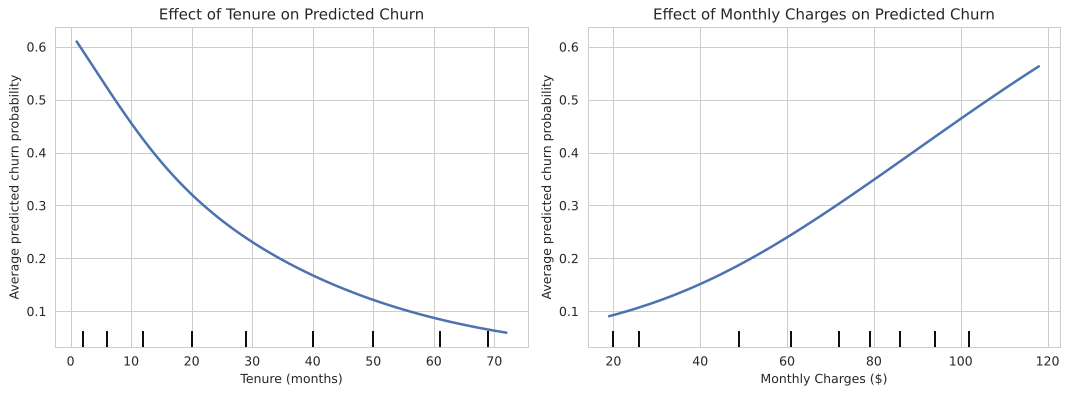

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# .astype(float): partial dependence needs float columns to build its grid of values
PartialDependenceDisplay.from_estimator(
    ann_pipeline, X_test_raw.astype(float), ["tenure", "MonthlyCharges"], ax=axes,
    line_kw={"color": "#4C72B0", "lw": 2}
)
axes[0].set_title("Effect of Tenure on Predicted Churn")
axes[0].set_xlabel("Tenure (months)")
axes[1].set_title("Effect of Monthly Charges on Predicted Churn")
axes[1].set_xlabel("Monthly Charges ($)")
for a in axes:
    a.set_ylabel("Average predicted churn probability")
plt.tight_layout()
plt.savefig("Model_Evaluation/partial_dependence.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:**
- **Tenure:** churn risk is highest for brand-new customers (about 60% predicted at month 1). It halves to about 30% by around 20 months and falls below 10% after about 5 years. The steepest drop is in the **first 12–18 months**, which is the critical window for retention.
- **Monthly charges:** risk rises steadily with the bill, from about 10% at $20/month to about 50% at around $105/month and higher beyond that. Higher spenders are more likely to leave (possibly price sensitivity or perceived value).

These match the raw data. Churn is 52.9% for customers in their first 6 months, compared with 9.5% for those beyond 4 years.

**Categorical attributes, "what-if" view:** for each categorical attribute, every test customer is given each value in turn (e.g. everyone set to Senior = Yes, then to Senior = No), and the average predicted churn is compared. This isolates the attribute's effect with everything else held fixed.

In [31]:
def avg_prob_if(changes):
    """Average predicted churn on the test set if every customer had these feature values."""
    X_mod = X_test_raw.copy()
    for col, val in changes.items():
        X_mod[col] = val
    return ann_pipeline.predict_proba(X_mod)[:, 1].mean()

contract_setting = {
    "Month-to-month": {"Contract_Month-to-month": 1, "Contract_One year": 0, "Contract_Two year": 0},
    "One year":       {"Contract_Month-to-month": 0, "Contract_One year": 1, "Contract_Two year": 0},
    "Two year":       {"Contract_Month-to-month": 0, "Contract_One year": 0, "Contract_Two year": 1},
}

rows = [{"attribute": "Contract", "setting": name, "avg_predicted_churn": avg_prob_if(ch)}
        for name, ch in contract_setting.items()]
for col, labels in {"InternetService": ("DSL", "Fiber optic"), "SeniorCitizen": ("No", "Yes"),
                    "Dependents": ("No", "Yes"), "MultipleLines": ("No", "Yes"),
                    "PhoneService": ("No", "Yes"), "gender": ("Female", "Male")}.items():
    for val, lab in zip((0, 1), labels):
        rows.append({"attribute": col, "setting": lab, "avg_predicted_churn": avg_prob_if({col: val})})

what_if = pd.DataFrame(rows)
what_if["range_within_attribute"] = what_if.groupby("attribute")["avg_predicted_churn"].transform(lambda s: s.max() - s.min())
what_if = what_if.sort_values(["range_within_attribute", "avg_predicted_churn"], ascending=[False, False])
what_if.to_csv("Model_Evaluation/what_if_categorical_effects.csv", index=False)
what_if.round(3).set_index(["attribute", "setting"])

avg_predicted_churn  range_within_attribute
attribute       setting                                                    
PhoneService    No                            0.370                   0.103
                Yes                           0.267                   0.103
SeniorCitizen   Yes                           0.364                   0.102
                No                            0.262                   0.102
Dependents      No                            0.291                   0.052
                Yes                           0.239                   0.052
Contract        Month-to-month                0.288                   0.024
                One year                      0.266                   0.024
                Two year                      0.263                   0.024
InternetService DSL                           0.287                   0.014
                Fiber optic                   0.273                   0.014
gender          Male                          0.284                   0.012
                Female                        0.273                   0.012
MultipleLines   No                            0.283                   0.008
                Yes                           0.275                   0.008

**Finding:**
- **Senior citizens** carry about 10 percentage points more predicted risk than non-seniors with the same tenure and bill (raw churn: 41.7% vs 23.6%).
- **Customers without phone service** show higher predicted risk *at the same monthly bill*. Treat this one with caution: only 682 customers (about 10%) have no phone service, so the comparison relies on combinations that are rare in the data. Its permutation importance is also small.
- **Dependents** lower risk a little in the model (about 5 points). The raw gap is larger (31.3% vs 15.5%), but much of it is explained by customers with dependents also tending to have longer tenure.
- **Contract type, internet service type, gender and multiple lines** change predicted churn by 2.4 points or less. They are not meaningful drivers in this dataset.

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Analyse predictions by segment and risk tier

## 9. Analyse Predictions

### 9.1 Predictions by Customer Segment (link to Clustering Analysis)

The test-set predictions are joined to the four K-Means segments from Part 2 via `row_id`. This checks whether the model's view of risk agrees with the segmentation, and how well it performs within each segment.

In [32]:
test_pred = pd.DataFrame({
    "row_id": test_df["row_id"].values,
    "Churn_actual": y_test,
    "churn_probability": p_test_ann,
    "churn_predicted": pred_test_ann,
}).merge(clusters_df, on="row_id", how="left", validate="one_to_one")

test_pred["tp"] = (test_pred["Churn_actual"] == 1) & (test_pred["churn_predicted"] == 1)
cluster_perf = test_pred.groupby(["cluster", "cluster_label"]).agg(
    customers=("row_id", "count"),
    actual_churn_rate=("Churn_actual", "mean"),
    avg_predicted_prob=("churn_probability", "mean"),
    flagged_at_risk=("churn_predicted", "mean"),
    churners=("Churn_actual", "sum"),
    flagged=("churn_predicted", "sum"),
    caught=("tp", "sum"),
).reset_index()
cluster_perf["recall"] = cluster_perf["caught"] / cluster_perf["churners"]
cluster_perf["precision"] = cluster_perf["caught"] / cluster_perf["flagged"].replace(0, np.nan)
cluster_perf = cluster_perf.drop(columns=["churners", "flagged", "caught"]).round(3)
test_pred = test_pred.drop(columns="tp")
cluster_perf

,cluster,cluster_label,customers,actual_churn_rate,avg_predicted_prob,flagged_at_risk,recall,precision
0,0,"New, High-Spend - Highest Risk",444,0.500,0.516,0.860,0.919,0.534
1,1,"New, Low-Spend - Elevated Risk",347,0.233,0.259,0.444,0.728,0.383
2,2,"Loyal, High-Spend - Low Risk",408,0.147,0.158,0.199,0.317,0.235
3,3,"Loyal, Low-Spend - Lowest Risk",210,0.052,0.043,0.014,0.091,0.333


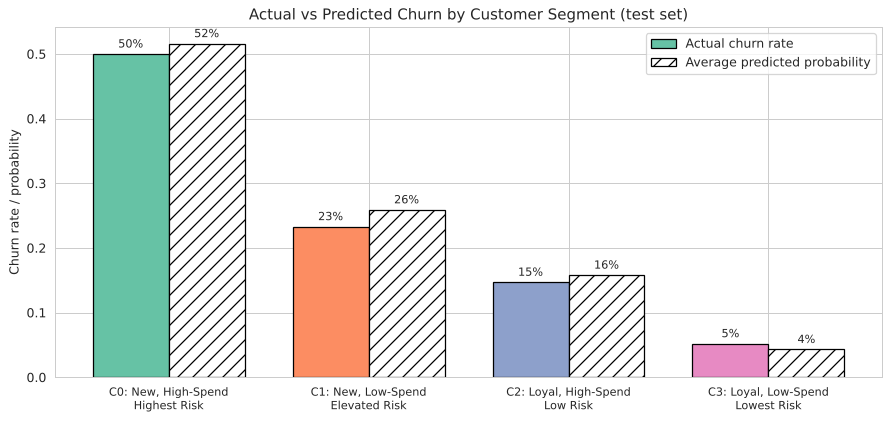

In [33]:
palette = sns.color_palette("Set2", 4)   # same colours as the Clustering notebook
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(cluster_perf))
w = 0.38
ax.bar(x - w / 2, cluster_perf["actual_churn_rate"], w, label="Actual churn rate", color=[palette[i] for i in cluster_perf["cluster"]], edgecolor="black")
ax.bar(x + w / 2, cluster_perf["avg_predicted_prob"], w, label="Average predicted probability", color="white", edgecolor="black", hatch="//")
for i, r in cluster_perf.iterrows():
    ax.text(i - w / 2, r["actual_churn_rate"] + 0.01, f"{r['actual_churn_rate']:.0%}", ha="center", fontsize=9)
    ax.text(i + w / 2, r["avg_predicted_prob"] + 0.01, f"{r['avg_predicted_prob']:.0%}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"C{c}: " + l.replace(" - ", "\n") for c, l in zip(cluster_perf["cluster"], cluster_perf["cluster_label"])], fontsize=9)
ax.set_ylabel("Churn rate / probability")
ax.set_title("Actual vs Predicted Churn by Customer Segment (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("Model_Evaluation/predicted_vs_actual_by_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

**Finding:**
- The ANN's average predicted probability closely matches the actual churn rate in every segment (e.g. 52% predicted vs 50% actual for Cluster 0). The model and the segmentation tell a **consistent story**.
- **Cluster 0 (New, High-Spend)**: the model flags 86% of these customers and catches **92% of the churners** in the segment. This is where the model and a segment-level campaign would overlap most.
- **Cluster 1 (New, Low-Spend)**: 73% of churners caught. This segment benefits most from customer-level scoring, because only part of it is high-risk.
- **Clusters 2 and 3 (Loyal)**: recall is low (32% and 9%). Churners in long-tenure segments look very similar to the loyal customers around them, so the model struggles to pick them out. The few churners there are hard to anticipate from these 11 attributes alone.

**Why combine the two:** clustering says *which group* a customer belongs to; the ANN says *how risky that individual is*. Within Cluster 1, for example, the ANN can separate the customers who need attention from the majority who don't.

### 9.2 Risk Tiers

For practical use, probabilities are grouped into three action tiers:

- **High** (probability ≥ 0.60): priority for proactive retention
- **Medium** (0.24–0.60): flagged by the model; lighter-touch engagement
- **Low** (< 0.24): not flagged

In [34]:
def risk_tier(p):
    if p >= 0.60:
        return "High"
    if p >= best_threshold:
        return "Medium"
    return "Low"

TIER_ORDER = ["High", "Medium", "Low"]
test_pred["risk_tier"] = pd.Categorical(test_pred["churn_probability"].apply(risk_tier), TIER_ORDER, ordered=True)

tier_summary = test_pred.groupby("risk_tier", observed=True).agg(
    customers=("row_id", "count"),
    actual_churn_rate=("Churn_actual", "mean"),
    churners=("Churn_actual", "sum"),
)
tier_summary["share_of_all_churners"] = tier_summary["churners"] / tier_summary["churners"].sum()
print(f"Tiers: High = probability >= 0.60, Medium = {best_threshold:.2f}-0.60, Low = below {best_threshold:.2f}")
tier_summary.round(3)

Tiers: High = probability >= 0.60, Medium = 0.24-0.60, Low = below 0.24

,customers,actual_churn_rate,churners,share_of_all_churners
risk_tier,,,,
High,207,0.676,140,0.374
Medium,413,0.346,143,0.382
Low,789,0.115,91,0.243


**Finding:** The tiers separate risk sharply.
- **High tier:** 15% of test customers, actual churn **67.6%**, containing about **37%** of all churners.
- **Medium tier:** churn 34.6% (above the 26.5% average), another 38% of churners.
- **Low tier:** churn only 11.5%.

A retention team that works only the High tier would reach over a third of all churners while contacting fewer than 1 in 6 customers.

### 9.3 Targeting Efficiency (Cumulative Gains)

Contacting the top 10% riskiest customers reaches 26.5% of churners (2.6x better than random)
Contacting the top 20% riskiest customers reaches 47.9% of churners (2.4x better than random)
Contacting the top 30% riskiest customers reaches 64.2% of churners (2.1x better than random)
Contacting the top 40% riskiest customers reaches 72.7% of churners (1.8x better than random)

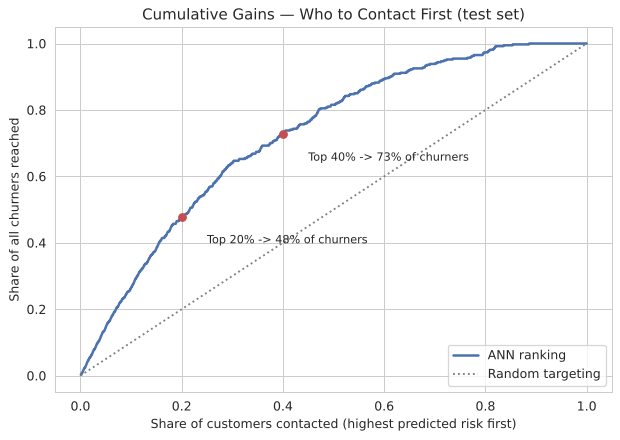

In [35]:
# Cumulative gains: contact customers from highest to lowest predicted risk
order = np.argsort(-p_test_ann)
cum_churners = np.cumsum(y_test[order]) / y_test.sum()
pct_contacted = np.arange(1, len(y_test) + 1) / len(y_test)

def captured_at(pct):
    return cum_churners[int(np.ceil(pct * len(y_test))) - 1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pct_contacted, cum_churners, color="#4C72B0", lw=2, label="ANN ranking")
ax.plot([0, 1], [0, 1], color="grey", ls=":", label="Random targeting")
for pct in (0.2, 0.4):
    ax.scatter(pct, captured_at(pct), color="#C44E52", zorder=3)
    ax.annotate(f"Top {pct:.0%} -> {captured_at(pct):.0%} of churners", (pct, captured_at(pct)),
                xytext=(pct + 0.05, captured_at(pct) - 0.08), fontsize=9)
ax.set_title("Cumulative Gains — Who to Contact First (test set)")
ax.set_xlabel("Share of customers contacted (highest predicted risk first)")
ax.set_ylabel("Share of all churners reached")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("Model_Evaluation/cumulative_gains.png", dpi=300, bbox_inches="tight")
plt.show()

for pct in (0.1, 0.2, 0.3, 0.4):
    print(f"Contacting the top {pct:.0%} riskiest customers reaches {captured_at(pct):.1%} of churners "
          f"({captured_at(pct) / pct:.1f}x better than random)")

**Finding:** Ranking customers by ANN probability makes retention campaigns much more efficient. Contacting the riskiest **20%** of customers reaches **48%** of churners, **2.4×** better than contacting customers at random. This is the most stakeholder-friendly way to present the model's value.

### 9.4 Error Analysis: Who Does the Model Get Wrong?

In [36]:
test_pred = test_pred.merge(test_df[["row_id"] + FEATURES], on="row_id", how="left")
test_pred["outcome"] = np.select(
    [(test_pred.Churn_actual == 1) & (test_pred.churn_predicted == 1),
     (test_pred.Churn_actual == 1) & (test_pred.churn_predicted == 0),
     (test_pred.Churn_actual == 0) & (test_pred.churn_predicted == 1)],
    ["Caught churner (TP)", "Missed churner (FN)", "False alarm (FP)"], default="Correctly clear (TN)")

error_profile = test_pred.groupby("outcome").agg(
    customers=("row_id", "count"),
    avg_tenure=("tenure", "mean"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    pct_month_to_month=("Contract_Month-to-month", "mean"),
    pct_fiber_optic=("InternetService", "mean"),
    pct_senior=("SeniorCitizen", "mean"),
    avg_predicted_prob=("churn_probability", "mean"),
).round(3)
error_profile

,customers,avg_tenure,avg_monthly_charges,pct_month_to_month,pct_fiber_optic,pct_senior,avg_predicted_prob
outcome,,,,,,,
Caught churner (TP),283,11.661,76.951,0.583,0.449,0.314,0.579
Correctly clear (TN),698,46.072,56.401,0.539,0.453,0.063,0.092
False alarm (FP),337,19.315,74.252,0.567,0.454,0.234,0.448
Missed churner (FN),91,40.714,69.637,0.538,0.495,0.077,0.145


**Finding:**
- **Missed churners (false negatives)** look like loyal customers. Their average tenure is about 41 months (vs about 12 for caught churners), and few are seniors. Their departure isn't explained by tenure or spend, so it is probably driven by factors **not in this dataset** (e.g. service quality, complaints, competitor offers, price changes).
- **False alarms (false positives)** look like churners: short tenure (about 19 months) and high bills (about $74). These are customers who fit the risk profile but stayed. For retention purposes they are still sensible people to engage, since their profile says they are at risk.
- **Implication:** adding behavioural data (support tickets, usage trends, payment history, satisfaction scores) is the most likely way to improve on the current recall/precision trade-off. Tuning this model further on the current 11 attributes is unlikely to help much, given how closely the ANN and logistic regression agree.

> 🗂️ **Jira Task — Sprint 3 (Epic: Predictive Modeling):** Export model and predictions for downstream use

## 10. Export Model and Predictions

### 10.1 Churn Scores for Every Customer

Every customer is scored and exported with their segment and risk tier, for the Business Analyst. The `split` column records which set each customer was in. **Only `test` rows give an unbiased view of accuracy**, because the model learned from the `train` rows and was tuned on the `validation` rows.

In [37]:
# Score every customer, recording which split each row was in
all_prob = ann_pipeline.predict_proba(full_df[FEATURES])[:, 1]
split_label = pd.Series("train", index=full_df.index)
split_label[val_df.index] = "validation"
split_label[test_df.index] = "test"

predictions_out = pd.DataFrame({
    "row_id": full_df["row_id"],
    "split": split_label.values,
    "Churn_actual": full_df[TARGET],
    "churn_probability": all_prob.round(4),
    "churn_predicted": (all_prob >= best_threshold).astype(int),
    "risk_tier": [risk_tier(p) for p in all_prob],
}).merge(clusters_df, on="row_id", how="left", validate="one_to_one")

predictions_out.to_csv("Predictions/churn_predictions.csv", index=False)
print(f"Exported {len(predictions_out):,} rows to Predictions/churn_predictions.csv")
print(predictions_out["split"].value_counts().to_string())
predictions_out.head()

Exported 7,043 rows to Predictions/churn_predictions.csv
split
train         4507
test          1409
validation    1127

,row_id,split,Churn_actual,churn_probability,churn_predicted,risk_tier,cluster,cluster_label
0,0,train,1,0.5545,1,Medium,1,"New, Low-Spend - Elevated Risk"
1,1,train,0,0.0352,0,Low,3,"Loyal, Low-Spend - Lowest Risk"
2,2,train,0,0.0158,0,Low,3,"Loyal, Low-Spend - Lowest Risk"
3,3,train,1,0.7596,1,High,0,"New, High-Spend - Highest Risk"
4,4,train,0,0.0258,0,Low,3,"Loyal, Low-Spend - Lowest Risk"


### 10.2 Save the Trained Model

The fitted scaler and ANN are saved together as one `Pipeline`, so the saved model takes **raw (unscaled) encoded values** directly, with no separate scaling step. The configuration and test metrics are saved alongside it as JSON. The check below reloads the model and confirms it reproduces the same predictions.

In [38]:
joblib.dump(ann_pipeline, "Model/ann_churn_pipeline.joblib")

model_config = {
    "model": "sklearn MLPClassifier (feed-forward ANN) inside a Pipeline with StandardScaler",
    "features_in_order": FEATURES,
    "hidden_layer_sizes": list(best_params["hidden_layer_sizes"]),
    "activation": best_params["activation"],
    "output_activation": "logistic (sigmoid)",
    "alpha_l2": best_params["alpha"],
    "optimizer": "adam",
    "learning_rate_init": float(final_lr),
    "batch_size": 64,
    "best_epoch": int(best_epoch),
    "decision_threshold": best_threshold,
    "risk_tiers": {"High": ">= 0.60", "Medium": f"{best_threshold:.2f} to 0.60", "Low": f"< {best_threshold:.2f}"},
    "test_metrics": test_metrics.loc["ANN (tuned threshold)"].drop("threshold").to_dict(),
}
with open("Model/model_config.json", "w") as f:
    json.dump(model_config, f, indent=2)

# Verify: the reloaded pipeline must reproduce exactly the same test predictions
loaded = joblib.load("Model/ann_churn_pipeline.joblib")
assert np.allclose(loaded.predict_proba(X_test_raw)[:, 1], p_test_ann), "Reloaded model gives different predictions!"
print("Saved Model/ann_churn_pipeline.joblib and Model/model_config.json, and verified the reload.")

Saved Model/ann_churn_pipeline.joblib and Model/model_config.json, and verified the reload.

**Using the saved model on a new customer** (encoded the same way as `full_encoded_cleaned.csv`):

In [39]:
# Example: score a new customer (raw, unscaled values in the same encoding as full_encoded_cleaned.csv)
new_customer = pd.DataFrame([{
    "gender": 0, "SeniorCitizen": 0, "Dependents": 0, "tenure": 3, "PhoneService": 1,
    "MultipleLines": 0, "InternetService": 1, "MonthlyCharges": 85,
    "Contract_Month-to-month": 1, "Contract_One year": 0, "Contract_Two year": 0,
}])[FEATURES]

prob = loaded.predict_proba(new_customer)[0, 1]
print(f"Predicted churn probability: {prob:.1%} -> risk tier: {risk_tier(prob)}")

Predicted churn probability: 76.6% -> risk tier: High

## 11. Summary

**What this notebook did:**
- Loaded and validated the Data Engineer's encoded dataset and the Part 2 cluster assignments
- Rebuilt the Data Engineer's 80/20 stratified train/test split and added a validation set; scaled features using training data only
- Set two baselines (majority class, logistic regression)
- **Defined the ANN architecture** through a 5-fold cross-validated search over 72 configurations. Final network: **11 → 32 → 16 → 1**, tanh hidden activations, sigmoid output, Adam optimiser, L2 regularisation (929 trainable parameters)
- **Trained the ANN and optimised convergence** with epoch-by-epoch monitoring, early stopping (best epoch 115) and a learning-rate comparison. The model converged smoothly with no overfitting
- Tuned the decision threshold (0.24) on the validation set to favour catching churners
- **Evaluated performance** once on the held-out test set, then checked calibration and the effect of duplicate rows
- **Identified the critical attributes** with permutation importance, partial dependence and what-if analysis
- **Analysed predictions** by customer segment, risk tier, targeting efficiency and error type
- Exported the trained model, configuration, churn scores for all customers, and all charts

**Key results for the final report:**

| Metric (test set, threshold 0.24) | Value |
|---|---|
| ROC-AUC | 0.807 |
| Recall (churners caught) | 75.7% (283 of 374) |
| Precision (flagged who really churn) | 45.6% |
| F1 | 0.569 |
| Top 20% riskiest customers contain | 47.9% of all churners |

**Key findings:**
1. **Tenure is the dominant churn driver**, followed by **monthly charges**. Risk is highest in the first 12–18 months and for customers on high bills. This independently confirms the Clustering Analysis.
2. **Senior citizens** are at higher risk; customers with **dependents** are slightly lower risk.
3. **Contract type, internet service, gender and multiple lines have little to no effect** on churn in this dataset, which differs from typical industry assumptions.
4. The ANN is **well calibrated** and agrees with the segmentation. Cluster 0 (New, High-Spend) is again the clear priority, and the model catches 92% of its churners.
5. The ANN performs **on par with logistic regression**. The churn signal in these attributes is close to linear, so the neural network adds no accuracy over a simpler model.

**Limitations (for the final report):**
- **Limited attributes:** only 11 demographic/account attributes are available. Missed churners look like loyal customers, which points to drivers outside this dataset (service experience, complaints, usage, competitor pricing).
- **Precision/recall trade-off:** at the chosen threshold, more than half of flagged customers would not have churned. The threshold should be set to match the retention budget and the cost of an offer.
- **Duplicates / no customer ID:** 6.6% of test rows have identical copies in training data. The effect on results was small (Section 7.5), but a unique customer ID is still recommended.
- **Point-in-time snapshot:** the model can't capture changes in behaviour over time and should be retrained periodically as new data arrives.
- **ANN-specific:** neural networks are less transparent than linear models, so explanations here rely on model-agnostic methods (permutation importance, partial dependence).

**Next step: Final Report (Stage 3-2).** The Business Analyst can use `Predictions/churn_predictions.csv` (risk score, tier and segment per customer) together with the charts in `Model_Evaluation/` to build targeted retention recommendations for each segment and risk tier.